# Анализ точек роста сервиса доставки

Сервис доставки еды «Всё.из.кафе» столкнулся со снижением заказов при стабильном притоке пользователей. Исследование объединяет анализ продуктовой воронки, RFM-сегментацию покупателей и K-Means-кластеризацию ресторанов.

Цели проекта:
- найти основные потери в пользовательском пути;
- определить сегменты для удержания и повторных заказов;
- выделить группы ресторанов с разными моделями работы;
- сформулировать рекомендации для продукта и партнёрского направления.

Данные содержат события пользователей, сведения о заказах, ресторанах, блюдах, выручке, доставке и комиссии.


## 1. Загрузка и предобработка данных

На первом этапе проверены структура данных, пропуски, типы полей, полные и неявные дубликаты.


In [1]:
#Заводим библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans


In [2]:
#Создаем датафрейм и выводим первые 5 строк
df = pd.read_csv('https://code.s3.yandex.net/datasets/insides_data.csv', parse_dates=['first_date','datetime'])
df.head(5)


,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,authorization,2021-05-01 16:07:53,NaN,NaN,NaN,NaN,NaN,NaN
1,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,reg_page,2021-05-01 16:09:16,NaN,NaN,NaN,NaN,NaN,NaN
2,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,confirm_phone,2021-05-01 16:09:19,NaN,NaN,NaN,NaN,NaN,NaN
3,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,login,2021-05-01 16:09:23,NaN,NaN,NaN,NaN,NaN,NaN
4,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,main_page,2021-05-01 16:09:34,2c6095730b514c189ee41c65f03febc3,NaN,NaN,NaN,NaN,NaN


In [3]:
#Выводим информацию о данных
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205510 entries, 0 to 205509
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   visitor_uuid  205510 non-null  object        
 1   user_id       205510 non-null  float64       
 2   device_type   205510 non-null  object        
 3   city_id       205510 non-null  int64         
 4   source        205510 non-null  object        
 5   first_date    205510 non-null  datetime64[ns]
 6   visit_id      205510 non-null  int64         
 7   event         205510 non-null  object        
 8   datetime      205510 non-null  datetime64[ns]
 9   rest_id       166915 non-null  object        
 10  object_id     21308 non-null   float64       
 11  order_id      7008 non-null    float64       
 12  revenue       7008 non-null    float64       
 13  delivery      7008 non-null    float64       
 14  commission    21308 non-null   float64       
dtypes: datetime64[ns]

Датафрейм содержит 205 510 строк и 15 столбцов.
Пропуски есть в столбцах rest_id, object_id, order_id, revenue, delivery и commission и связаны со структурой идентификаторов ресторанов, заказов и блюд. Количество полей в столбцах order_id, revenue и delivery совпадают.
Некоторые столбцы с id имеют тип float64, что не критично, но смущает


In [4]:
#Посмотрим количество уникальных значений в столбцах с id
id_list = df[['visitor_uuid', 'user_id', 'rest_id', 'object_id', 'order_id']]

for el in id_list:
    print(el, id_list[el].nunique())


visitor_uuid 8891
user_id 8473
rest_id 21
object_id 603
order_id 4443


In [5]:
#Преобразуем поля в id в целочисленный тип
df['user_id'] = df['user_id'].astype('int64')


In [6]:
#Проверим дубликаты
df.duplicated().sum()


0

Полных дубликатов в датафрейме не обнаружено


In [7]:
#Проверим распределние значении в категориальных столбцах, чтобы найти неявные дубли
categorial = df[['device_type', 'source', 'event']]
for el in categorial:
    print(categorial[el].value_counts(normalize=True))


Desktop    0.774264
Mobile     0.225736
Name: device_type, dtype: float64
organic     0.494210
Source_B    0.298939
Source_C    0.158425
Source_A    0.048426
Name: source, dtype: float64
main_page        0.708515
login            0.090414
object_page      0.059034
authorization    0.048577
reg_page         0.027658
add_to_cart      0.027381
confirm_phone    0.021152
order            0.017269
Name: event, dtype: float64


Неявных дублей не найдено


## 2. Анализ пользовательского пути

Общая воронка показывает путь от авторизации до заказа. Дополнительное сравнение мобильной и десктопной версий помогает локализовать платформенные различия.


### 2.1. Общая продуктовая воронка


,event,visitors_n,conversions_%
0,authorization,7796,100.000000
1,main_page,6835,87.673166
2,reg_page,5649,72.460236
3,confirm_phone,4347,55.759364
4,object_page,3530,45.279631
5,add_to_cart,2929,37.570549
6,order,2432,31.195485


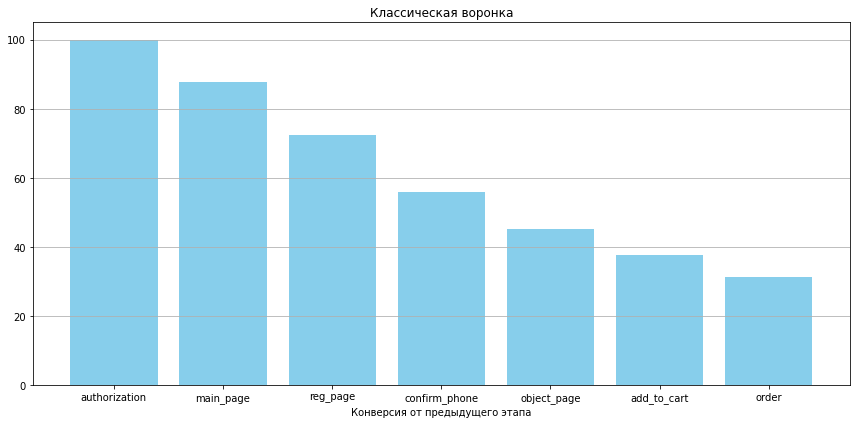

In [8]:
#Создаем визуализацию классической воронки
#Создаем столбец с понедельной разбивкой
df['first_week'] = df['first_date'].dt.to_period('W').dt.to_timestamp()

#Задаем этапы воронки
funnel_steps = ['authorization', 'main_page', 'reg_page', 'confirm_phone', 'object_page', 'add_to_cart', 'order']



#Учитываем только события из воронки
funnel_df = df[df['event'].isin(funnel_steps)]
#Считаем для каждого события количество уникальных user_id
funnel_df = funnel_df.groupby('event')['visitor_uuid'].nunique().reindex(funnel_steps).reset_index().rename(columns={'visitor_uuid':'visitors_n'})
#Считаем общее количество уникальных визитов
first_step_visitors = funnel_df.iloc[0]['visitors_n']
#Создаем столбец с конверсией предыдущего шага
funnel_df['conversions_%'] = funnel_df['visitors_n'] / first_step_visitors * 100

display(funnel_df)
#Визуализируем данные в график
plt.figure(figsize=(12,6))
plt.bar(funnel_df['event'], funnel_df['conversions_%'], color='skyblue')
plt.title('Классическая воронка')
plt.xlabel('Конверсия от предыдущего этапа')
plt.tight_layout()
plt.grid(axis='y')

plt.show()


Воронка состоит из семи этапов: авторизация, главная страница, регистрация, подтверждение телефона, карточка блюда, корзина и заказ. До заказа доходят 31,2% посетителей. Наиболее заметная общая потеря возникает между регистрацией и подтверждением телефона: конверсия на этом переходе составляет около 77%.


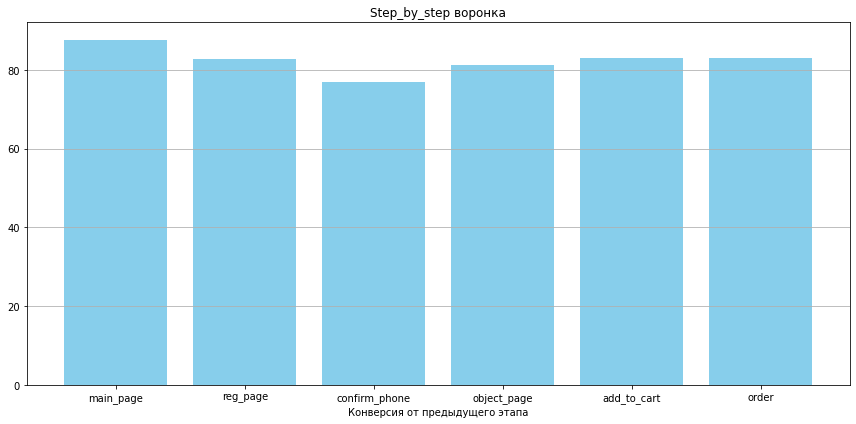

In [9]:
#Создаем визуализацию step_by_step ворокни

#Создаем столбец с конверсией предыдущего шага
funnel_df['conversions_from_prev_step_%'] = funnel_df['visitors_n'] / funnel_df['visitors_n'].shift(1) * 100

#Визуализируем данные в график
plt.figure(figsize=(12,6))
plt.bar(funnel_df['event'], funnel_df['conversions_from_prev_step_%'], color='skyblue')
plt.title('Step_by_step воронка')
plt.xlabel('Конверсия от предыдущего этапа')
plt.tight_layout()
plt.grid(axis='y')
plt.show()


Наибольшая пошаговая потеря также наблюдается между регистрацией и подтверждением номера телефона.


### 2.2. Сравнение мобильной и десктопной воронок


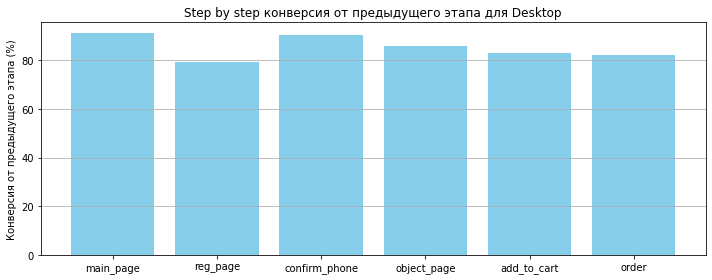

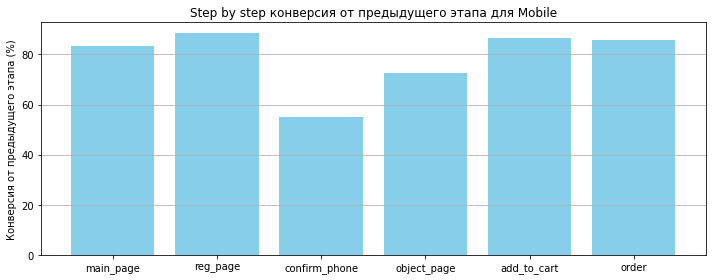

In [10]:
#Строим таблицу step_by_step воронки по устройствам
segment = 'device_type'
unique_platform = df['device_type'].unique()

#Заводим цикл расчета конверсии предыдущего шага в разрезе устройств
for device in unique_platform :
    funnel_df = df[(df['event'].isin(funnel_steps)) & (df['device_type'] == device)]
    funnel_df = funnel_df.groupby('event')['user_id'].nunique().reindex(funnel_steps).reset_index()
    funnel_df = funnel_df.rename(columns={'user_id': 'users_n'})
    funnel_df['conversion_from_previous_step_%'] = funnel_df['users_n'] / funnel_df['users_n'].shift(1) * 100

    # Cтроим простой график воронки
    plt.figure(figsize=(10, 4))
    plt.bar(funnel_df['event'], funnel_df['conversion_from_previous_step_%'], color='skyblue')
    plt.title(f'Step by step конверсия от предыдущего этапа для {device}')
    plt.ylabel('Конверсия от предыдущего этапа (%)')
    plt.tight_layout()
    plt.grid(axis='y')
    plt.show()


Десктопная воронка проходит этап подтверждения телефона стабильнее. В мобильной версии на этом шаге теряется 44,95% пользователей. После верификации мобильная аудитория проходит этапы карточки блюда, корзины и заказа немного лучше десктопной.


## 3. RFM-сегментация покупателей

Покупатели сгруппированы по давности последнего заказа, частоте покупок и суммарной выручке.


### 3.1. Расчёт Recency, Frequency и Monetary Value


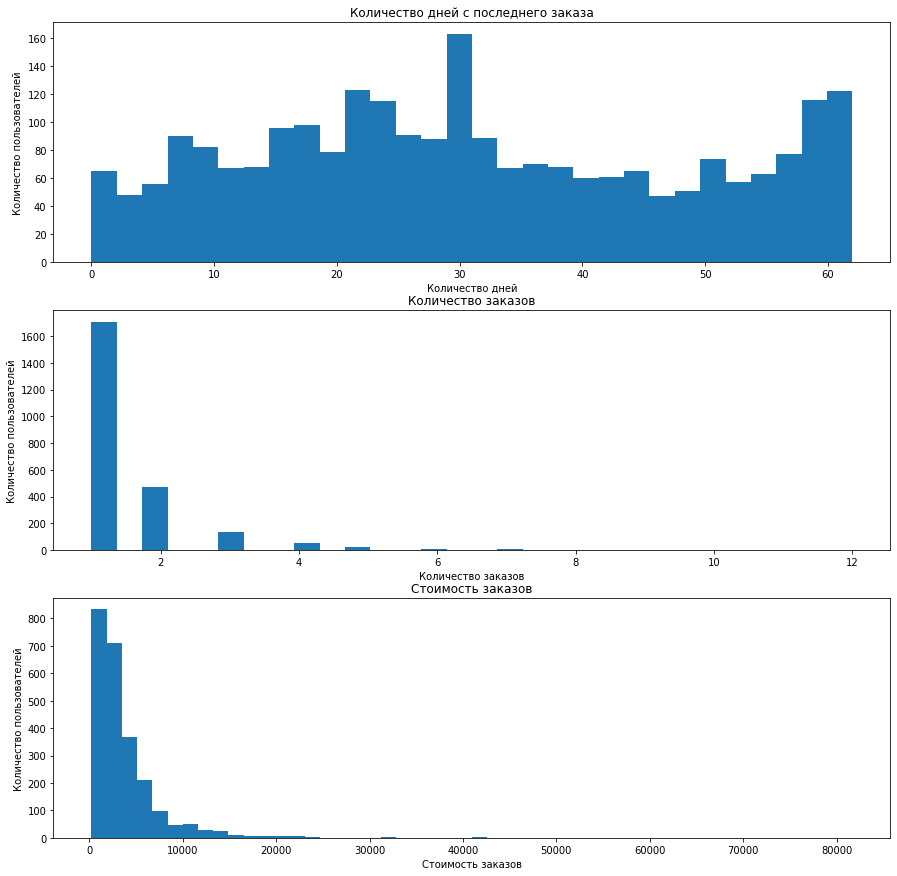

In [11]:
#Создаем столбец с количеством дней после события
df['order_recency'] = pd.to_datetime('2021-07-03') - df['datetime']
#Оставляем только строки где была выручка
df_rfm = df[df['event'] == 'order']

# Группируем данные для каждого пользователя и рассчитываем данные для RFM-анализа:
rfm = df_rfm.groupby('user_id').agg(
    # Количество дней с последнего заказа:    
    recency = ('order_recency', lambda x: x.min().days),
    # Количество заказов за период времени: 
    frequency = ('order_id', 'count'),
    # Сумма стоимости всех заказов: 
    monetary_value = ('revenue', 'sum')
).reset_index()

#Визуализируем данные с помощью гистрограм
fig,axes = plt.subplots(3, 1, figsize=(15,15))

axes[0].hist(rfm['recency'],bins=30)
axes[0].set_title('Количество дней с последнего заказа')
axes[0].set_xlabel('Количество дней')
axes[0].set_ylabel('Количество пользователей')

axes[1].hist(rfm['frequency'],bins=30)
axes[1].set_title('Количество заказов')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество пользователей')

axes[2].hist(rfm['monetary_value'],bins=50)
axes[2].set_title('Стоимость заказов')
axes[2].set_xlabel('Стоимость заказов')
axes[2].set_ylabel('Количество пользователей')

plt.show()


Количество дней с последнего заказа имеет широкий диапазон значений с пиком на 30-й день и небольшим ростом в конце периода, что может говорить о том, чаще покупают раз в месяц или два месяца.
Основная доля пользователей совершила один заказ.
Распределение размера выручки смещено влево и приобладает сегмент пользователей которые принесли до 4 000 рублей дохода


### 3.2. Формирование и анализ RFM-сегментов


In [12]:
# Определяем группу пользователя по количеству дней с момента последнего заказа: 
rfm['r'] = pd.cut(rfm['recency'], bins=3, labels=[3,2,1])

# Определяем группу пользователя по количеству заказов: 
rfm['f'] = pd.cut(rfm['frequency'], [0, 1, 2, np.inf], labels=[1,2,3], include_lowest=True)

# Определяем группу пользователя по сумме стоимости заказов: 
rfm['m'] = pd.qcut(rfm['monetary_value'], q=3, labels=[1,2,3])

# Находим групповой RFM-индекс:
rfm[['r','f','m']] = rfm[['r','f','m']].astype('str')
rfm['rfm_group'] = rfm['r'] + rfm['f'] + rfm['m']

# Выводим первые строки таблицы:
print(rfm.head(3))


   user_id  recency  frequency  monetary_value  r  f  m rfm_group
0     5506       32          2         3752.00  2  2  3       223
1     6291       57          1         1750.00  1  1  1       111
2     6820       41          1         1260.14  2  1  1       211


In [13]:
# Группируем данные по сегментам и считаем их размер:
rfm = rfm.groupby('rfm_group').agg({'user_id':'nunique'}).reset_index()

# Считаем долю пользователей в каждом сегменте:
rfm['user_share'] = rfm['user_id'] / rfm['user_id'].sum()

# Выводим результат:
print(rfm.sort_values(by='user_id', ascending=False))


   rfm_group  user_id  user_share
8        211      281    0.116308
0        111      247    0.102235
17       311      246    0.101821
9        212      237    0.098096
1        112      216    0.089404
18       312      186    0.076987
10       213      122    0.050497
13       223      115    0.047599
16       233      102    0.042219
19       313       99    0.040977
22       323       88    0.036424
5        123       85    0.035182
2        113       75    0.031043
24       333       68    0.028146
12       222       59    0.024421
21       322       48    0.019868
4        122       45    0.018626
7        133       41    0.016970
3        121       16    0.006623
15       232        9    0.003725
20       321        9    0.003725
11       221        8    0.003311
6        132        8    0.003311
23       332        5    0.002070
14       231        1    0.000414


В анализ вошли 2 416 покупателей. Один заказ совершили 70,74% пользователей. Сегменты с одним заказом и низким monetary value (`111`, `211`, `311`) объединяют 32,04% покупателей. Активный высокочастотный и высокодоходный сегмент `333` составляет 2,81% аудитории.

Основная точка роста — перевод клиента от первой покупки ко второй. Для недавних покупателей подходят сценарии онбординга и персональных рекомендаций, для уходящих — реактивационные коммуникации, а для сегмента `333` — механики лояльности без массовых скидок.


## 4. K-Means-кластеризация ресторанов

Рестораны сегментированы по объёму заказов, среднему чеку и ширине заказанного ассортимента.


### 4.1. Подготовка признаков ресторанов


In [14]:
#Создаем переменную в которой считаем показатели по каждому ресторану
df_new = df[df['event'] == 'order'].groupby('rest_id').agg(
    # общее количество заказов:    
    total_orders = ('order_id', 'nunique'),
    # средняя стоимость заказа: 
    avg = ('revenue', 'mean'),
    # общее число заказанных уникальных блюд: 
    total_dishes  = ('object_id', 'nunique')
).fillna(0)


### 4.2. Стандартизация и выбор числа кластеров


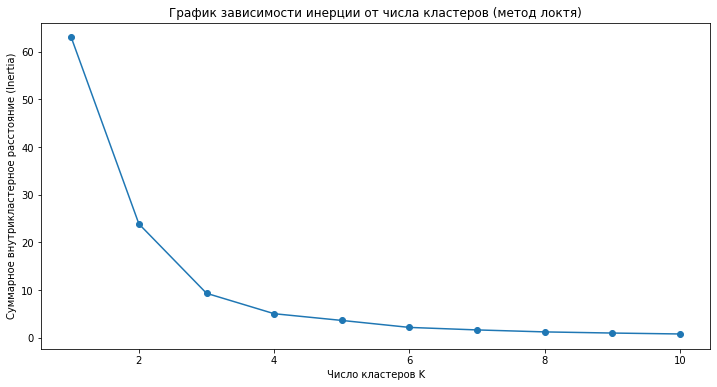

In [15]:
from sklearn.preprocessing import StandardScaler
# Выделяем признаки для кластеризации
features = ['total_orders', 'avg', 'total_dishes']
X = df_new[features].values

# Нормализация данных
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X)

i = []

min_k = 1
max_k = 10
plt.figure(figsize=(12,6))

# Цикл для перебора разного числа кластеров
for k in range(min_k, max_k+1):  
   km = KMeans(n_clusters=k)  
   km.fit_transform(X_normalized) 
   i.append(km.inertia_) 

# Строим график зависимости инерции от количества кластеров
plt.plot(range(min_k, max_k+1), i, marker='o')
plt.xlabel('Число кластеров K') 
plt.ylabel('Суммарное внутрикластерное расстояние (Inertia)') 
plt.title('График зависимости инерции от числа кластеров (метод локтя)') 
plt.show()


Кривая inertia заметно меняет наклон в районе трёх кластеров, поэтому для интерпретации выбрано `k = 3`.


### 4.3. Обучение и интерпретация K-Means


In [16]:
#Проводим итоговую кластеризацию
kmeans_fin = KMeans(n_clusters=3, random_state=42, n_init=10)
df_new['clusters'] = kmeans_fin.fit_predict(X_normalized)

#Анализируем средние значения признаков в кластерах
cluster_analysis = df_new.groupby('clusters').agg(
    avg_orders = ('total_orders', 'mean'),
    avg_price = ('avg', 'mean'),
    avg_dishes = ('total_dishes', 'mean')
    ).round(2)
print(cluster_analysis)


          avg_orders  avg_price  avg_dishes
clusters                                   
0              69.60    2167.86           9
1            1100.00    2498.83          83
2              76.25    4048.50           5


Модель выделила три группы:

- **15 основных партнёров:** в среднем 70 заказов, чек около 2 168 рублей и 9 заказанных блюд;
- **2 высокообъёмных лидера:** в среднем 1 100 заказов, чек около 2 499 рублей и 83 блюда;
- **4 нишевых ресторана с высоким чеком:** в среднем 76 заказов, чек около 4 049 рублей и 5 блюд.

Два ресторана-лидера формируют 2 200 из 3 549 заказов, представленных событием `order`, то есть около 62%.


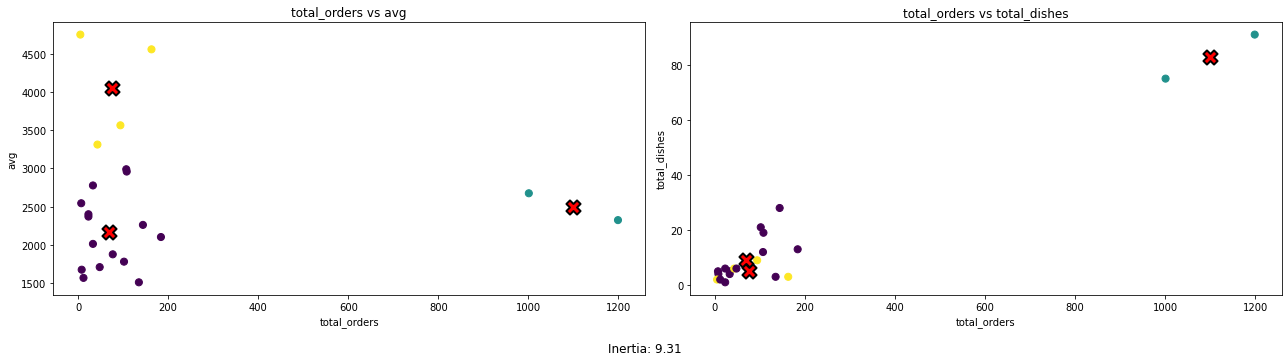

In [17]:
# Получаем координаты центров (центроидов) кластеров
centroids = kmeans_fin.cluster_centers_

#Преобразуем центройды в исходное пространство
centroids_original = scaler.inverse_transform(centroids)

# Создаём 2 графика (1 строка × 2 столбца) для отображения попарных комбинаций признаков
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Перебираем пары признаков: 
for i, (x_idx, y_idx) in enumerate([[0, 1], [0, 2]]):
   x_label, y_label = features[x_idx], features[y_idx]  # Названия признаков для осей

   # Строим точки — объекты из датафрейма, раскрашенные по меткам кластера
   axes[i].scatter(
       df_new[x_label],  # Значения по оси X
       df_new[y_label],  # Значения по оси Y
       c=df_new['clusters'],  # Цвет зависит от номера кластера
       cmap='viridis',  # Цветовая карта
       s=50  # Размер точек
   )

   # Строим центроиды кластеров красными крестами
   axes[i].scatter(
       centroids_original[:, x_idx],  # X-координаты центров
       centroids_original[:, y_idx],  # Y-координаты центров
       s=200,  # Размер крестов
       c='red',  # Цвет — красный
       edgecolors='black',  # Обводка — чёрная
       linewidths=2,  # Толщина обводки
       marker='X'  # Форма маркера — крест
   )

   # Подписи осей и заголовок графика
   axes[i].set_xlabel(x_label)
   axes[i].set_ylabel(y_label)
   axes[i].set_title(f'{x_label} vs {y_label}')

# Подгоняем макет, оставляя место снизу для подписи с инерцией
plt.tight_layout(rect=[0, 0.05, 1, 1])

# Добавляем текст с СВР внизу графика (по центру)
fig.text(0.5, 0.01, f'Inertia: {kmeans_fin.inertia_:.2f}', ha='center', fontsize=12)

# Показываем итоговый набор визуализаций
plt.show()


Количество заказов тесно связано с шириной заказанного ассортимента, тогда как явной связи со средним чеком на этой небольшой выборке не наблюдается. Это описательная зависимость, а не доказательство того, что расширение меню само по себе увеличит спрос.


## 5. Итоговый вывод и рекомендации


1. Приоритетная продуктовая проблема — подтверждение телефона в мобильной версии, где теряется 44,95% пользователей. Перед изменением интерфейса стоит добавить диагностику ошибок и провести A/B-тест нового сценария.
2. 70,74% покупателей совершили один заказ. RFM-коммуникации следует сфокусировать на переходе ко второй покупке: онбординг для недавних клиентов, реактивация уходящих и программы лояльности для сегмента `333`.
3. Два ресторана-лидера формируют около 62% заказов, представленных событием `order`. Это одновременно сильная сторона и риск концентрации: важно удерживать этих партнёров и искать рестораны с похожими характеристиками.
4. Кластеризация построена только по 21 ресторану и трём признакам. Перед использованием сегментов в операционных решениях следует проверить устойчивость кластеров и дополнить признаки маржинальностью, отменами, скоростью доставки, рейтингом и географией.
